# Solar-System Acceleration from Quasar Proper Motions — Catalogue × Galactic-Cut Grid

Runs the `quaia_sbi.ipynb` pipeline (steps 1–10) over **6 data cases** and
**2 models**, and reports the dipole **(gx, gy, gz)** plus its **sky direction**
in ICRS and galactic coordinates.

| | galcut 0° | galcut 20° | galcut 30° |
|---|---|---|---|
| **gaia**  | ✓ | ✓ | ✓ |
| **quaia** | ✓ | ✓ | ✓ |

**Models** (identical to the reference notebook):

| Model | θ | x |
|---|---|---|
| `full` | alm (ℓ ≤ 3, 30) + Cℓ_E, Cℓ_B (ℓ = 4–10, 14) = **44** | VSH fit to ℓ ≤ 10 = **240** |
| `det`  | alm (ℓ ≤ 3) = **30** | VSH fit to ℓ ≤ 3 = **30** |

**Pipeline per case** — pixelize (nside 64, |b| > galcut) → `WeightedSHT` normal
matrix + LU → per-pixel noise Cholesky → x_obs from the real maps → N simulations
from the prior → SNPE → posterior at x_obs → (gx, gy, gz) via `s2g` → direction.

Everything is cached under `results/gaia_quaia_cases/`; rerunning the notebook
reuses simulations, trained posteriors and posterior samples. Delete a file to
force that step to recompute.

In [ ]:
from pathlib import Path

# Folder holding the input catalogues (quaia_G20.0_with_pmra_pmdec_corr.csv,
# gaia_qso_edata_5_params.csv, ...). Change this one line to relocate the data.
DATA_DIR = Path('../data')   # relative to notebooks/, i.e. <repo>/data

## 0. Imports

In [1]:
import functools
import gc
import sys
import time
from pathlib import Path

REPO = Path("..").resolve()   # repository root (kernel cwd = notebooks/)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))   # make sbi_qpm importable even without `pip install -e .`

import numpy as np
import pandas as pd
import healpy as hp
import matplotlib.pyplot as plt
import torch

from sbi.inference import SNPE, simulate_for_sbi
from sbi.utils.user_input_checks import check_sbi_inputs, process_prior, process_simulator

from sbi_qpm.geometry import SkyFunction, direction_summary
from sbi_qpm.data import load_gaia_qso, compute_pixel_stats
from sbi_qpm.forward_model import WeightedSHT
from sbi_qpm.sbi_setup import (
    n_real_params,
    precompute_noise_cholesky,
    create_prior_full,
    create_prior_det,
    simulator_full,
    simulator_det,
)

import matplotlib as mpl
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Liberation Serif'],
    'text.latex.preamble': r'\usepackage{newtxtext}\usepackage{newtxmath}',
})

/home/phuy2808/Astrophysis/Intern_apc/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/phuy2808/Astrophysis/Intern_apc/myenv/lib/python3.12/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


## 1. Configuration

All numbers below match `quaia_sbi.ipynb`. `N_ENSEMBLE > 1` trains several
nets on the *same* simulations and pools their posterior samples — the mixture
marginalises over SNPE training noise (which averaging point estimates would
hide). It costs one extra training per net, so it is off by default.

In [2]:
nside      = 64
npix       = hp.nside2npix(nside)
lmax_sig   = 3       # ℓ ≤ 3 : deterministic signal parameters in θ
lmax_fit   = 10      # ℓ ≤ 10: VSH fit used as summary statistic x

n_alm_l3   = n_real_params(lmax_sig)        # 30
n_Cl       = 2 * (lmax_fit - lmax_sig)      # 14  (Cl_E[4..10] + Cl_B[4..10])
n_theta    = n_alm_l3 + n_Cl                # 44
n_summary  = n_real_params(lmax_fit)        # 240

alm_bound  = 50e-3   # mas/yr
Cl_bound   = 130e-6   # (mas/yr)²

N_SIMS      = 100_000   # simulations per (case, model)
N_POSTERIOR = 10000  # posterior draws per net
N_ENSEMBLE  = 1         # nets per (case, model); samples pooled if > 1
SEED        = 0

# 'quaia' means Quaia ∩ Gaia-QSO on source_id, exactly as in `quaia_sbi copy.ipynb`
# (both catalogues then carry the same 5-parameter Gaia astrometry).
QUAIA_CROSSMATCH_GAIA = True

CATALOGS = ['gaia', 'quaia']
GALCUTS  = [0, 20, 30]
CASES    = [(cat, gc) for cat in CATALOGS for gc in GALCUTS]

CACHE_DIR = REPO / 'results/gaia_quaia_cases_v3'
CACHE_DIR.mkdir(parents=True, exist_ok=True)

dipole_idx = np.array([0, lmax_sig, lmax_sig + 1])   # θ indices of the ℓ=1 E-modes
skyfunc    = SkyFunction(nside=nside)

def case_tag(catalog, galcut):
    # Cl_bound is part of the tag: changing the prior changes the simulations,
    # so runs at different bounds must not share a cache entry.
    return (f"{catalog}_galcut{galcut:02d}_nside{nside}_N{N_SIMS}"
            f"_Cl{Cl_bound*1e6:g}")

print(f"{len(CASES)} cases × 2 models = {2 * len(CASES)} SNPE runs")
print(f"θ dim: full {n_theta}, det {n_alm_l3};  x dim: full {n_summary}, det {n_alm_l3}")
print(f"cache → {CACHE_DIR}")

6 cases × 2 models = 12 SNPE runs
θ dim: full 44, det 30;  x dim: full 240, det 30
cache → /home/phuy2808/Astrophysis/Intern_apc/results/gaia_quaia_cases_v3


## 2. Load Catalogues

Read once; each case re-pixelizes the same source table with its own galactic cut.

In [3]:
_gaia  = load_gaia_qso(DATA_DIR / 'gaia_qso_edata_5_params.csv')
_quaia = load_gaia_qso(DATA_DIR / 'quaia_G20.0_with_pmra_pmdec_corr.csv')

def get_table(catalog):
    if catalog == 'gaia':
        return _gaia
    if catalog == 'quaia':
        return (_quaia.merge(_gaia[['source_id']], on='source_id', how='inner')
                if QUAIA_CROSSMATCH_GAIA else _quaia)
    raise ValueError(catalog)

for cat in CATALOGS:
    print(f"{cat:6s}: {len(get_table(cat)):,} sources after cuts")

gaia  : 1,215,942 sources after cuts
quaia : 634,401 sources after cuts


## 3. Per-Case Setup

Pixel statistics → `WeightedSHT` (normal matrix + cached LU for both lmax) →
per-pixel noise Cholesky → real-data summaries `x_obs` (ℓ ≤ 10) and `x_obs_l3` (ℓ ≤ 3).

In [4]:
def build_case(catalog, galcut):
    '''Everything that depends on the data but not on the model or the prior.'''
    tab = get_table(catalog)
    px = compute_pixel_stats(
        tab['ra'].values, tab['dec'].values,
        tab['pmra'].values, tab['pmdec'].values,
        tab['pmra_error'].values, tab['pmdec_error'].values,
        tab['pmra_pmdec_corr'].values,
        nside=nside, galcut=galcut,
    )

    # Non-finite noise → 0 so those pixels get zero weight in C⁻¹
    sig_ra  = np.where(np.isfinite(px['sig_pmra_wm']),  px['sig_pmra_wm'],  0.0)
    sig_dec = np.where(np.isfinite(px['sig_pmdec_wm']), px['sig_pmdec_wm'], 0.0)
    corr    = np.nan_to_num(px['pm_corr_wm'], nan=0.0)

    solver = WeightedSHT(nside, px['mask'], px['pmra_wm'], px['pmdec_wm'],
                         sig_ra, sig_dec, corr)
    solver.build_lu(lmax_fit)    # 240×240 — full model
    solver.build_lu(lmax_sig)    #  30×30  — det. model

    L11, L21, L22, valid_pix = precompute_noise_cholesky(
        sig_ra, sig_dec, corr, px['mask'], npix)

    best_fit_l10 = solver.solve_fast(px['pmra_wm'], px['pmdec_wm'], lmax_fit)
    best_fit_l3  = solver.solve_fast(px['pmra_wm'], px['pmdec_wm'], lmax_sig)

    # Point-estimate dipole straight from the VSH fit (indices depend on the fit lmax)
    g_l10 = np.array(skyfunc.s2g(best_fit_l10[[0, lmax_fit, lmax_fit + 1]] * 1e3))
    g_l3  = np.array(skyfunc.s2g(best_fit_l3[dipole_idx] * 1e3))

    return dict(
        catalog=catalog, galcut=galcut, tag=case_tag(catalog, galcut),
        solver=solver, L11=L11, L21=L21, L22=L22, valid_pix=valid_pix,
        x_obs=torch.tensor(best_fit_l10, dtype=torch.float32),
        x_obs_l3=torch.tensor(best_fit_l3, dtype=torch.float32),
        g_fit_l10=g_l10, g_fit_l3=g_l3,
        n_src=len(tab), n_pix=int(px['mask'].sum()),
    )

## 4. Simulate → Train → Sample (cached)

`simulate_once` and `run_model` each short-circuit on an existing cache file.
The two models never share simulations: the summary statistic itself differs
(240-dim ℓ ≤ 10 fit vs 30-dim ℓ ≤ 3 fit).

In [5]:
def make_simulator(case, model):
    '''Model-specific forward simulator bound to this case's noise and mask.'''
    common = dict(solver=case['solver'], L11=case['L11'], L21=case['L21'],
                  L22=case['L22'], valid_pix=case['valid_pix'], npix=npix,
                  lmax_sig=lmax_sig, lmax_fit=lmax_fit, n_alm_l3=n_alm_l3)
    if model == 'full':
        sim = functools.partial(simulator_full, n_Cl=n_Cl, **common)
        return lambda theta: sim(theta)[0]          # (x, pmra, pmdec) → x
    return functools.partial(simulator_det, **common)


def make_prior(model):
    return (create_prior_full(n_alm_l3, n_Cl, alm_bound, Cl_bound) if model == 'full'
            else create_prior_det(n_alm_l3, alm_bound))


def simulate_once(case, model, prior_proc, sim_proc):
    '''Training set for one (case, model). Cached; delete the .npz to re-simulate.'''
    path = CACHE_DIR / f"sims_{case['tag']}_{model}.npz"
    if path.exists():
        d = np.load(path)
        print(f"  [{case['tag']} | {model}] sims cached → {path.name}")
        return (torch.tensor(d['theta'], dtype=torch.float32),
                torch.tensor(d['x'], dtype=torch.float32))

    print(f"  [{case['tag']} | {model}] simulating {N_SIMS:,} …")
    t0 = time.time()
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    theta_s, x_s = simulate_for_sbi(sim_proc, proposal=prior_proc,
                                    num_simulations=N_SIMS)
    np.savez(path, theta=theta_s.numpy(), x=x_s.numpy(),
             galcut=case['galcut'], catalog=case['catalog'], seed=SEED)
    print(f"    done in {(time.time() - t0) / 60:.1f} min → {path.name}")
    return theta_s, x_s


def run_model(case, model):
    '''Posterior samples at the real-data summary for one (case, model).

    Returns (pooled, per_net) with shapes
    (N_ENSEMBLE * N_POSTERIOR, dim) and (N_ENSEMBLE, N_POSTERIOR, dim).
    '''
    tag = case['tag']
    samples_path = CACHE_DIR / f"samples_{tag}_{model}_ens{N_ENSEMBLE}.npz"
    if samples_path.exists():
        per_net = np.load(samples_path)['samples']
        print(f"  [{tag} | {model}] samples cached → {samples_path.name}")
        return per_net.reshape(-1, per_net.shape[-1]), per_net

    prior = make_prior(model)
    prior_proc, _, prior_np = process_prior(prior)
    sim_proc = process_simulator(make_simulator(case, model), prior_proc, prior_np)
    check_sbi_inputs(sim_proc, prior_proc)

    theta_s, x_s = simulate_once(case, model, prior_proc, sim_proc)
    x_target = case['x_obs'] if model == 'full' else case['x_obs_l3']

    per_net = []
    for k in range(N_ENSEMBLE):
        post_path = CACHE_DIR / f"post_{tag}_{model}_net{k}.pt"
        if post_path.exists():
            posterior = torch.load(post_path, weights_only=False)
            print(f"  [{tag} | {model}] net {k} cached → {post_path.name}")
        else:
            print(f"  [{tag} | {model}] training net {k} …")
            t0 = time.time()
            torch.manual_seed(10_000 * (SEED + 1) + k)   # varies the net, not the sims
            inference = SNPE(prior=prior_proc).append_simulations(theta_s, x_s)
            posterior = inference.build_posterior(inference.train())
            torch.save(posterior, post_path)
            print(f"    trained in {(time.time() - t0) / 60:.1f} min")

        with torch.no_grad():
            s = posterior.sample((N_POSTERIOR,), x=x_target, show_progress_bars=False)
        per_net.append(s.cpu().numpy())

    per_net = np.stack(per_net)
    np.savez(samples_path, samples=per_net, galcut=case['galcut'],
             catalog=case['catalog'], model=model)
    return per_net.reshape(-1, per_net.shape[-1]), per_net

## 5. Run All Cases

One case at a time; the solver, simulations and training set of each case are
released before the next one starts (a 100k × 240 float32 training set is ~100 MB).

In [6]:
results = {}     # (catalog, galcut, model) -> dict(samples=…, per_net=…, g=…)
case_info = {}   # (catalog, galcut)        -> n_src, n_pix, fit-only dipole

for catalog, galcut in CASES:
    print(f"\n=== {catalog} | galcut {galcut}° " + "=" * 40)
    t0 = time.time()
    case = build_case(catalog, galcut)
    print(f"  {case['n_src']:,} sources → {case['n_pix']:,} valid pixels")
    print(f"  VSH-fit dipole (ℓ≤10): gx={case['g_fit_l10'][0]:6.2f} "
          f"gy={case['g_fit_l10'][1]:6.2f} gz={case['g_fit_l10'][2]:6.2f} µas/yr")

    for model in ('full', 'det'):
        pooled, per_net = run_model(case, model)
        results[(catalog, galcut, model)] = dict(samples=pooled, per_net=per_net)

    case_info[(catalog, galcut)] = {k: case[k] for k in
                                    ('n_src', 'n_pix', 'g_fit_l10', 'g_fit_l3')}
    del case
    gc.collect()
    print(f"  case done in {(time.time() - t0) / 60:.1f} min")

print(f"\nAll {len(results)} (case, model) posteriors ready.")


=== gaia | galcut 0° ========================================
  1,215,942 sources → 43,182 valid pixels
  VSH-fit dipole (ℓ≤10): gx=  0.43 gy= -4.43 gz= -2.45 µas/yr
  [gaia_galcut00_nside64_N100000_Cl130 | full] samples cached → samples_gaia_galcut00_nside64_N100000_Cl130_full_ens1.npz
  [gaia_galcut00_nside64_N100000_Cl130 | det] samples cached → samples_gaia_galcut00_nside64_N100000_Cl130_det_ens1.npz
  case done in 0.0 min

=== gaia | galcut 20° ========================================
  1,215,942 sources → 32,349 valid pixels
  VSH-fit dipole (ℓ≤10): gx=  8.87 gy= -4.62 gz=  1.43 µas/yr
  [gaia_galcut20_nside64_N100000_Cl130 | full] samples cached → samples_gaia_galcut20_nside64_N100000_Cl130_full_ens1.npz
  [gaia_galcut20_nside64_N100000_Cl130 | det] samples cached → samples_gaia_galcut20_nside64_N100000_Cl130_det_ens1.npz
  case done in 0.0 min

=== gaia | galcut 30° ========================================
  1,215,942 sources → 24,580 valid pixels
  VSH-fit dipole (ℓ≤10): gx= 

## 6. Dipole (gx, gy, gz) and Sky Direction

`s2g` maps the ℓ = 1 E-mode coefficients θ[0, 3, 4] to the Cartesian ICRS dipole
in µas/yr. `direction_summary` then reduces the posterior cloud of directions to:

* **centre** — direction of the mean unit vector (`ra_c, dec_c`; `l_c, b_c`).
  Component-wise medians of RA/Dec are not a valid centre for a direction.
* **marginal 16/84** — percentiles unwrapped about that centre, so an RA
  posterior straddling 0°/360° is still reported sensibly.
* **θ₆₈, θ₉₅** — angular radii containing 68% / 95% of the sampled directions.
* **R** — length of the mean resultant vector; R → 1 tight, R → 0 isotropic.

In [7]:
def extract_g(samples_np):
    '''Posterior samples → (N, 3) dipole (gx, gy, gz) in µas/yr.'''
    s = samples_np[:, dipole_idx] * 1e3          # mas/yr → µas/yr
    return np.column_stack(skyfunc.s2g(s.T))


def summarize(catalog, galcut, model):
    g = extract_g(results[(catalog, galcut, model)]['samples'])
    results[(catalog, galcut, model)]['g'] = g

    q16, q50, q84 = np.percentile(g, [16, 50, 84], axis=0)
    mag = np.linalg.norm(g, axis=1)
    m16, m50, m84 = np.percentile(mag, [16, 50, 84])
    d = direction_summary(g)
    info = case_info[(catalog, galcut)]

    row = dict(catalog=catalog, galcut=galcut, model=model,
               n_src=info['n_src'], n_pix=info['n_pix'])
    for i, name in enumerate(('gx', 'gy', 'gz')):
        row[name] = q50[i]
        row[f'{name}_lo'] = q50[i] - q16[i]
        row[f'{name}_hi'] = q84[i] - q50[i]
    row.update(gmag=m50, gmag_lo=m50 - m16, gmag_hi=m84 - m50,
               sig_gmag=m50 / ((m84 - m16) / 2))
    for k in ('ra_c', 'dec_c', 'l_c', 'b_c', 'R', 'theta_68', 'theta_95'):
        row[k] = d[k]
    # Signed offsets from the centre: normally lo < 0 < hi, but the mean-vector
    # centre can sit outside the marginal 16/84 range when the posterior is broad,
    # so the sign is kept rather than folded into a ± symbol.
    for k in ('ra', 'dec', 'l', 'b'):
        row[f'{k}_lo'] = ((d[f'{k}_16'] - d[f'{k}_c'] + 180) % 360) - 180
        row[f'{k}_hi'] = ((d[f'{k}_84'] - d[f'{k}_c'] + 180) % 360) - 180
    return row


summary = pd.DataFrame([summarize(cat, gc, m)
                        for cat, gc in CASES for m in ('full', 'det')])
summary.to_csv(CACHE_DIR / 'summary.csv', index=False)
print(f"saved → {CACHE_DIR / 'summary.csv'}")
summary

saved → /home/phuy2808/Astrophysis/Intern_apc/results/gaia_quaia_cases_v3/summary.csv


,catalog,galcut,model,n_src,n_pix,gx,gx_lo,gx_hi,gy,gy_lo,...,theta_68,theta_95,ra_lo,ra_hi,dec_lo,dec_hi,l_lo,l_hi,b_lo,b_hi
0,gaia,0,full,1215942,43182,0.337491,0.587910,0.616948,-4.520036,0.456760,...,8.832889,14.472674,-7.547256,7.682846,-4.830763,5.348339,-5.603851,5.724862,-6.133380,6.121222
1,gaia,0,det,1215942,43182,-0.144917,0.360604,0.359940,-4.063171,0.314264,...,6.181856,10.021125,-5.068008,5.088704,-3.794220,4.012623,-3.954075,3.982260,-4.160156,4.123213
2,gaia,20,full,1215942,32349,4.074734,1.889395,1.828875,-3.591021,1.542973,...,23.796588,41.517331,-18.323540,18.419892,-13.173039,14.673811,-19.182910,19.188358,-15.108121,18.184426
3,gaia,20,det,1215942,32349,-0.077674,0.466606,0.465356,-3.453544,0.384070,...,8.184912,13.387758,-7.584765,7.763276,-4.591820,5.094884,-4.819626,4.744083,-5.913628,6.110363
4,gaia,30,full,1215942,24580,-0.854018,4.223495,4.243708,-4.243673,2.717106,...,43.148148,68.740068,-41.136807,61.767723,-12.342963,32.803075,-23.038179,23.291273,-34.273615,35.549998
5,gaia,30,det,1215942,24580,-0.590994,0.754952,0.772486,-3.016099,0.570907,...,13.769934,23.345750,-13.323870,14.487173,-7.367027,8.933855,-7.216183,7.151434,-10.992469,10.943975
6,quaia,0,full,634401,41398,1.011642,0.717974,0.715635,-4.938395,0.552534,...,10.440603,16.847002,-7.961089,7.844406,-6.166812,6.474332,-6.847083,6.966121,-6.852298,7.040736
7,quaia,0,det,634401,41398,0.040854,0.422135,0.419028,-4.296116,0.367899,...,6.891810,11.197047,-5.628158,5.602642,-4.149773,4.481586,-4.453103,4.474501,-4.662129,4.654571
8,quaia,20,full,634401,32282,4.724571,1.892964,1.950529,-3.995863,1.518941,...,21.212650,36.385290,-16.135390,16.320659,-11.850946,13.324894,-16.864492,17.426217,-13.802902,16.200015
9,quaia,20,det,634401,32282,0.106150,0.522855,0.524550,-3.699466,0.414959,...,9.014324,14.865647,-8.059987,8.188277,-5.088801,5.624654,-5.356214,5.362541,-6.459704,6.614757


### 6a. Report — dipole components and amplitude

In [8]:
print(f"{'case':>22s} {'model':>5s} | "
      f"{'gx [µas/yr]':>19s} {'gy [µas/yr]':>19s} {'gz [µas/yr]':>19s} "
      f"{'|g| [µas/yr]':>19s} {'|g|/σ':>6s}")
print('-' * 135)
for _, r in summary.iterrows():
    case = f"{r.catalog} galcut {r.galcut:g}°"
    cols = ''.join(f"{r[c]:8.2f} +{r[f'{c}_hi']:4.2f} -{r[f'{c}_lo']:4.2f}"
                   for c in ('gx', 'gy', 'gz', 'gmag'))
    print(f"{case:>22s} {r.model:>5s} | {cols} {r.sig_gmag:6.1f}")

                  case model |         gx [µas/yr]         gy [µas/yr]         gz [µas/yr]        |g| [µas/yr]  |g|/σ
---------------------------------------------------------------------------------------------------------------------------------------
        gaia galcut 0°  full |     0.34 +0.62 -0.59   -4.52 +0.46 -0.46   -2.59 +0.43 -0.44    5.28 +0.43 -0.43   12.4
        gaia galcut 0°   det |    -0.14 +0.36 -0.36   -4.06 +0.33 -0.31   -2.78 +0.34 -0.34    4.94 +0.33 -0.31   15.4
       gaia galcut 20°  full |     4.07 +1.83 -1.89   -3.59 +1.49 -1.54   -1.85 +1.43 -1.46    6.14 +1.66 -1.59    3.8
       gaia galcut 20°   det |    -0.08 +0.47 -0.47   -3.45 +0.38 -0.38   -2.86 +0.38 -0.39    4.53 +0.38 -0.38   12.0
       gaia galcut 30°  full |    -0.85 +4.24 -4.22   -4.24 +2.83 -2.72   -4.91 +2.96 -3.07    8.30 +2.73 -2.54    3.2
       gaia galcut 30°   det |    -0.59 +0.77 -0.75   -3.02 +0.55 -0.57   -2.83 +0.58 -0.59    4.30 +0.54 -0.54    7.9
       quaia galcut 0°  full |  

### 6b. Report — direction (ICRS and galactic)

In [9]:
print(f"{'case':>22s} {'model':>5s} | {'RA [°]':>22s} {'Dec [°]':>22s} "
      f"{'l [°]':>22s} {'b [°]':>22s} {'θ68':>6s} {'θ95':>6s} {'R':>6s}")
print('-' * 159)
for _, r in summary.iterrows():
    case = f"{r.catalog} galcut {r.galcut:g}°"
    cols = ''.join(f"{r[f'{c}_c']:8.2f} {r[f'{c}_lo']:+6.1f}/{r[f'{c}_hi']:+6.1f}"
                   for c in ('ra', 'dec', 'l', 'b'))
    print(f"{case:>22s} {r.model:>5s} | {cols} "
          f"{r.theta_68:6.1f} {r.theta_95:6.1f} {r.R:6.3f}")

print("\nCentre = direction of the mean unit vector; the two numbers after it are the")
print("16/84 percentiles as signed offsets from that centre (unwrapped for RA and l).")
print("θ68 / θ95 = angular radius containing 68% / 95% of posterior directions [°].")
print("R = mean resultant length: R → 1 tight, R → 0 isotropic (posterior ≈ prior).")

                  case model |                 RA [°]                Dec [°]                  l [°]                  b [°]    θ68    θ95      R
---------------------------------------------------------------------------------------------------------------------------------------------------------------
        gaia galcut 0°  full |   274.33   -7.5/  +7.7  -29.83   -4.8/  +5.3    2.63   -5.6/  +5.7   -6.44   -6.1/  +6.1    8.8   14.5  0.989
        gaia galcut 0°   det |   267.94   -5.1/  +5.1  -34.36   -3.8/  +4.0  356.02   -4.0/  +4.0   -3.91   -4.2/  +4.1    6.2   10.0  0.995
       gaia galcut 20°  full |   317.33  -18.3/ +18.4  -18.96  -13.2/ +14.7   29.63  -19.2/ +19.2  -38.65  -15.1/ +18.2   23.8   41.5  0.921
       gaia galcut 20°   det |   268.66   -7.6/  +7.8  -39.65   -4.6/  +5.1  351.71   -4.8/  +4.7   -7.06   -5.9/  +6.1    8.2   13.4  0.991
       gaia galcut 30°  full |   257.86  -41.1/ +61.8  -48.72  -12.3/ +32.8  339.85  -23.0/ +23.3   -5.42  -34.3/ +35.5   43.1   68.

### 6c. Is the direction consistent with the Galactic centre?

A $\chi^2$ test on the two components of $(g_x, g_y, g_z)$ **transverse** to the
target direction $\hat n$. Only those carry direction information: the amplitude
uncertainty projects entirely onto $\hat n$ and drops out, so the test is not
diluted by how well $|g|$ is measured, and there is no longitude wrap or
$\cos b$ metric to worry about (as there would be testing $(l, b)$ directly).

$$u_k = (g_k\cdot\hat e_1,\; g_k\cdot\hat e_2), \qquad
\chi^2 = \bar u^{\top} C_u^{-1} \bar u \quad (2\ \mathrm{dof}),$$

with $\hat e_1, \hat e_2$ spanning the plane $\perp \hat n$, $\bar u$ the
posterior mean and $C_u$ its sample covariance. `sig` is the equivalent Gaussian
$\sigma$ of the 2-dof $p$-value (`norm.isf(p/2)`) — *not* the mean/$\sigma$ ratio
that `|g|/σ` reports.

The statement is a posterior-credibility one: a small $p$ means the target
direction sits inside the credible region of the *direction* posterior, not
that a repeated-sampling test failed to reject.

Two targets: the Galactic centre, and the Gaia EDR3 measured acceleration
direction. A small $\chi^2$ only means *consistent*, not *detected* — read it
next to `|g|/σ`, `θ68` and `R`, which say whether the posterior constrains the
direction at all.

In [17]:
# ── 6c. chi^2: dipole direction vs Galactic centre ────────────────────────
from scipy.stats import chi2 as chi2_dist, norm
from sbi_qpm.geometry import icrs_to_galactic

# Galactic (l, b) = (0, 0) in ICRS. Sgr A* sits 0.07 deg away — irrelevant next
# to the ~10 deg posterior widths, but the choice is stated rather than implied.
TARGETS = {
    'GC':   (266.40499, -28.93617),
    # Gaia EDR3 solar-system acceleration, Gaia Collaboration (Klioner+ 2021):
    # 5.05 uas/yr toward (ra, dec) = (269.1, -31.6) deg.
    'EDR3': (269.1, -31.6),
}
_l, _b = icrs_to_galactic(*TARGETS['GC'])
assert abs(_b[0]) < 1e-2 and min(abs(_l[0]), abs(_l[0] - 360)) < 1e-2, 'GC frame round-trip failed'


def chi2_direction(g, ra_t, dec_t):
    """chi^2 (2 dof) that the posterior dipole `g` (N, 3) points at (ra_t, dec_t).

    Returns (chi2, p, sigma_equivalent, separation of the mean direction [deg]).
    """
    n = np.asarray(skyfunc.dir2vec(ra_t, dec_t), dtype=float).ravel()
    tmp = np.array([0., 0., 1.]) if abs(n[2]) < 0.9 else np.array([1., 0., 0.])
    e1 = np.cross(n, tmp); e1 /= np.linalg.norm(e1)
    e2 = np.cross(n, e1)                       # (n, e1, e2) orthonormal
    u = np.column_stack([g @ e1, g @ e2])      # transverse components [uas/yr]
    ubar = u.mean(axis=0)
    x2 = float(ubar @ np.linalg.solve(np.cov(u.T), ubar))
    p = float(chi2_dist.sf(x2, 2))
    nbar = g.mean(axis=0); nbar /= np.linalg.norm(nbar)
    sep = float(np.degrees(np.arccos(np.clip(nbar @ n, -1.0, 1.0))))
    return x2, p, float(norm.isf(p / 2)), sep


chi2_rows = []
for cat, gc_deg in CASES:
    for model in ('full', 'det'):
        g = results[(cat, gc_deg, model)]['g']
        s = summary[(summary.catalog == cat) & (summary.galcut == gc_deg)
                    & (summary.model == model)].iloc[0]
        row = dict(catalog=cat, galcut=gc_deg, model=model,
                   l_c=s.l_c, b_c=s.b_c, sig_gmag=s.sig_gmag,
                   theta_68=s.theta_68, R=s.R)
        for tag, (ra_t, dec_t) in TARGETS.items():
            x2, p, sig, sep = chi2_direction(g, ra_t, dec_t)
            row.update({f'sep_{tag}': sep, f'chi2_{tag}': x2,
                        f'p_{tag}': p, f'sig_{tag}': sig})
        chi2_rows.append(row)

chi2_dir = pd.DataFrame(chi2_rows)
chi2_dir.to_csv(CACHE_DIR / 'direction_chi2.csv', index=False)

hdr = (f"{'case':>22s} {'model':>5s} | {'l [°]':>7s} {'b [°]':>7s} "
       f"{'|g|/σ':>6s} {'θ68':>6s} {'R':>5s} |")
for tag in TARGETS:
    hdr += f" {'sep_' + tag:>8s} {'χ²':>6s} {'p':>7s} {'σ':>5s} |"
print(hdr)
print('-' * len(hdr))
for _, r in chi2_dir.iterrows():
    line = (f"{r.catalog + f' galcut {r.galcut:g}°':>22s} {r.model:>5s} | "
            f"{r.l_c:7.2f} {r.b_c:7.2f} {r.sig_gmag:6.1f} {r.theta_68:6.1f} {r.R:5.3f} |")
    for tag in TARGETS:
        line += (f" {r[f'sep_{tag}']:7.1f}° {r[f'chi2_{tag}']:6.2f} "
                 f"{r[f'p_{tag}']:7.4f} {r[f'sig_{tag}']:5.2f} |")
    print(line)

print("\nsep = angle between the posterior mean direction and the target [°].")
print("χ² has 2 dof (transverse components only). σ = norm.isf(p/2) is the equivalent")
print("Gaussian level of the *direction* posterior at the target — a posterior-credibility")
print("statement, not a repeated-sampling test, and unrelated to the |g|/σ column.")
print(f"saved → {CACHE_DIR / 'direction_chi2.csv'}")


                  case model |   l [°]   b [°]  |g|/σ    θ68     R |   sep_GC     χ²       p     σ | sep_EDR3     χ²       p     σ |
------------------------------------------------------------------------------------------------------------------------------------
        gaia galcut 0°  full |    2.63   -6.44   12.4    8.8 0.989 |     7.0°   1.12  0.5726  0.56 |     4.9°   0.56  0.7561  0.31 |
        gaia galcut 0°   det |  356.02   -3.91   15.4    6.2 0.995 |     5.6°   1.96  0.3750  0.89 |     2.9°   0.54  0.7627  0.30 |
       gaia galcut 20°  full |   29.63  -38.65    3.8   23.8 0.921 |    48.2°   5.35  0.0689  1.82 |    45.9°   5.07  0.0794  1.75 |
       gaia galcut 20°   det |  351.71   -7.06   12.0    8.2 0.991 |    10.9°   4.68  0.0963  1.66 |     8.1°   2.78  0.2493  1.15 |
       gaia galcut 30°  full |  339.85   -5.42    3.2   43.1 0.773 |    20.8°   0.79  0.6746  0.42 |    18.9°   0.68  0.7101  0.37 |
       gaia galcut 30°   det |  345.26   -2.50    7.9   13.8 0.974 | 

## 7. Comparison Across Cases

Full model in blue, deterministic-only in orange. Error bars are the 16/84
posterior percentiles.

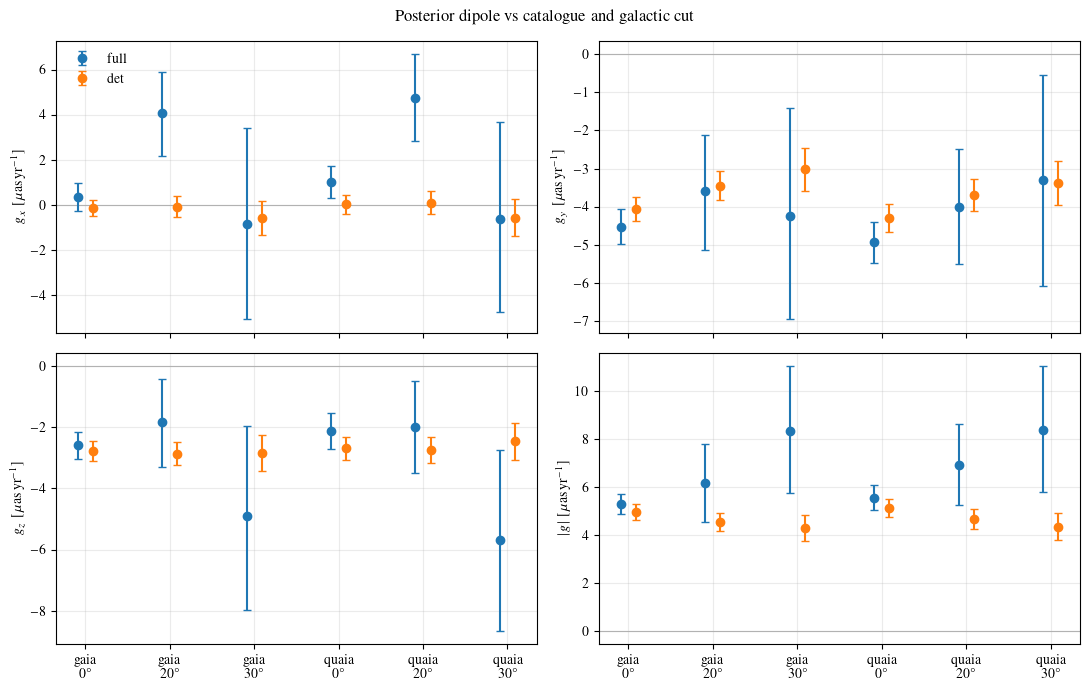

In [10]:
order  = [(c, g) for c in CATALOGS for g in GALCUTS]
xlab   = [f"{c}\n{g}°" for c, g in order]
xpos   = np.arange(len(order))
colors = {'full': 'tab:blue', 'det': 'tab:orange'}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, key, lab in zip(axes.ravel(),
                        ('gx', 'gy', 'gz', 'gmag'),
                        (r'$g_x$', r'$g_y$', r'$g_z$', r'$|g|$')):
    for model, dx in (('full', -0.09), ('det', 0.09)):
        sub = summary[summary.model == model].set_index(['catalog', 'galcut'])
        vals = np.array([sub.loc[k, key] for k in order])
        err  = np.array([[sub.loc[k, f'{key}_lo'] for k in order],
                         [sub.loc[k, f'{key}_hi'] for k in order]])
        ax.errorbar(xpos + dx, vals, yerr=err, fmt='o', capsize=3,
                    color=colors[model], label=model if key == 'gx' else None)
    ax.axhline(0, color='0.7', lw=0.8, zorder=0)
    ax.set_ylabel(lab + r'  $[\mu\mathrm{as\,yr}^{-1}]$')
    ax.grid(alpha=0.25)
axes[0, 0].legend(frameon=False)
for ax in axes[1]:
    ax.set_xticks(xpos)
    ax.set_xticklabels(xlab)
fig.suptitle('Posterior dipole vs catalogue and galactic cut')
fig.tight_layout()
fig.savefig(REPO / 'output/gxyz_cases_gaia_quaia.pdf', bbox_inches='tight')
plt.show()

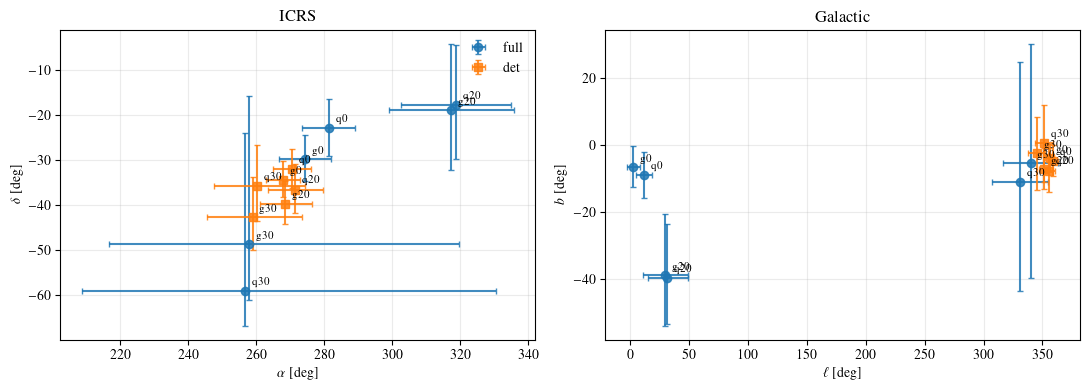

In [11]:
AXLAB = {'ra': r'$\alpha$ [deg]', 'dec': r'$\delta$ [deg]',
         'l': r'$\ell$ [deg]',    'b': r'$b$ [deg]'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (lon, lat, frame) in zip(axes, [('ra', 'dec', 'ICRS'), ('l', 'b', 'Galactic')]):
    for model, marker in (('full', 'o'), ('det', 's')):
        sub = summary[summary.model == model].set_index(['catalog', 'galcut'])
        for (cat, gc) in order:
            r = sub.loc[(cat, gc)]
            ax.errorbar(r[f'{lon}_c'], r[f'{lat}_c'],
                        xerr=[[abs(r[f'{lon}_lo'])], [abs(r[f'{lon}_hi'])]],
                        yerr=[[abs(r[f'{lat}_lo'])], [abs(r[f'{lat}_hi'])]],
                        fmt=marker, capsize=2, color=colors[model], alpha=0.85,
                        label=model if (cat, gc) == order[0] else None)
            ax.annotate(f'{cat[0]}{gc:g}', (r[f'{lon}_c'], r[f'{lat}_c']),
                        textcoords='offset points', xytext=(5, 4), fontsize=8)
    ax.set_xlabel(AXLAB[lon])
    ax.set_ylabel(AXLAB[lat])
    ax.set_title(frame)
    ax.grid(alpha=0.25)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(REPO / 'output/direction_cases_gaia_quaia.pdf', bbox_inches='tight')
plt.show()

## 8. Posterior-Predictive Check — Observed vs Simulated Proper Motions

Draw `N_PPC` θ from each case's posterior, push every draw through the *same*
forward model used for training (signal alm → spin-1 map + correlated per-pixel
noise), and compare the pixel-value distribution of the resulting maps against
the real weighted-mean maps over the same valid pixels.

This is the check that the inference is being run on a simulator that actually
reproduces the data: a posterior that nails the dipole but sits on a simulator
with the wrong noise level or wrong ℓ > 3 power shows up here as a width
mismatch, so agreement is necessary (not sufficient) for section 6 to mean
anything.

Cases are rebuilt here because section 5 releases them; that costs a few
seconds each.

In [12]:
import gc          # a stray top-level `for cat, gc in ...` rebinds this to an int
from sbi_qpm.sbi_setup import simulator_full

N_PPC     = 100            # posterior draws per case
PPC_MODEL = 'full'         # 'det' truncates the signal at ℓ = 3
PPC_NBIN  = 80
PPC_CLIP  = (0.5, 99.5)    # percentiles of the observed map spanned by the bins
COMPS     = ('pmra', 'pmdec')


def predictive_maps(theta_row, model, common):
    '''One posterior-predictive (pmra, pmdec) map pair, per-pixel noise included.

    A `det` draw is a `full` draw with every Cℓ(ℓ>3) set to zero, so both models
    reuse the shipped simulator instead of a re-implementation that could drift.
    '''
    th = np.asarray(theta_row, dtype=np.float32)
    if model == 'det':
        th = np.concatenate([th, np.zeros(n_Cl, dtype=np.float32)])
    _, pmra, pmdec = simulator_full(torch.tensor(th), n_Cl=n_Cl, **common)
    return pmra, pmdec


def ppc_case(case, model, rng):
    '''Observed pixel values and posterior-predictive histograms for one case.'''
    common = dict(solver=case['solver'], L11=case['L11'], L21=case['L21'],
                  L22=case['L22'], valid_pix=case['valid_pix'], npix=npix,
                  lmax_sig=lmax_sig, lmax_fit=lmax_fit, n_alm_l3=n_alm_l3)
    vp = case['valid_pix']
    samples = results[(case['catalog'], case['galcut'], model)]['samples']
    idx = rng.choice(len(samples), size=N_PPC, replace=False)

    obs  = {'pmra': case['solver'].pm_ra_map[vp], 'pmdec': case['solver'].pm_dec_map[vp]}
    bins = {k: np.linspace(*np.percentile(v, PPC_CLIP), PPC_NBIN + 1)
            for k, v in obs.items()}
    hist = {k: [] for k in COMPS}
    rms  = {k: [] for k in COMPS}

    for i in idx:
        maps = dict(zip(COMPS, predictive_maps(samples[i], model, common)))
        for k in COMPS:
            hist[k].append(np.histogram(maps[k][vp], bins=bins[k], density=True)[0])
            rms[k].append(maps[k][vp].std())

    return {k: dict(obs=obs[k], bins=bins[k], hist=np.array(hist[k]),
                    obs_rms=float(obs[k].std()), sim_rms=float(np.mean(rms[k])))
            for k in COMPS}


rng = np.random.default_rng(SEED)
ppc = {}
for catalog, galcut in CASES:
    t0 = time.time()
    case = build_case(catalog, galcut)
    ppc[(catalog, galcut)] = ppc_case(case, PPC_MODEL, rng)
    del case
    gc.collect()
    d = ppc[(catalog, galcut)]
    print(f"  {catalog:5s} galcut {galcut:2d}° — {N_PPC} maps in {time.time() - t0:.0f} s"
          f"   rms obs/model:"
          f"  µα* {d['pmra']['obs_rms']*1e3:5.1f}/{d['pmra']['sim_rms']*1e3:5.1f}"
          f"  µδ {d['pmdec']['obs_rms']*1e3:5.1f}/{d['pmdec']['sim_rms']*1e3:5.1f} µas/yr")

  gaia  galcut  0° — 100 maps in 4 s   rms obs/model:  µα* 123.0/120.7  µδ 106.9/103.8 µas/yr
  gaia  galcut 20° — 100 maps in 4 s   rms obs/model:  µα*  73.8/ 73.8  µδ  64.9/ 64.4 µas/yr
  gaia  galcut 30° — 100 maps in 3 s   rms obs/model:  µα*  65.5/ 66.8  µδ  59.9/ 60.1 µas/yr
  quaia galcut  0° — 100 maps in 4 s   rms obs/model:  µα* 100.2/102.0  µδ  88.5/ 88.9 µas/yr
  quaia galcut 20° — 100 maps in 3 s   rms obs/model:  µα*  76.7/ 78.1  µδ  67.1/ 68.2 µas/yr
  quaia galcut 30° — 100 maps in 5 s   rms obs/model:  µα*  70.2/ 70.5  µδ  63.3/ 63.4 µas/yr


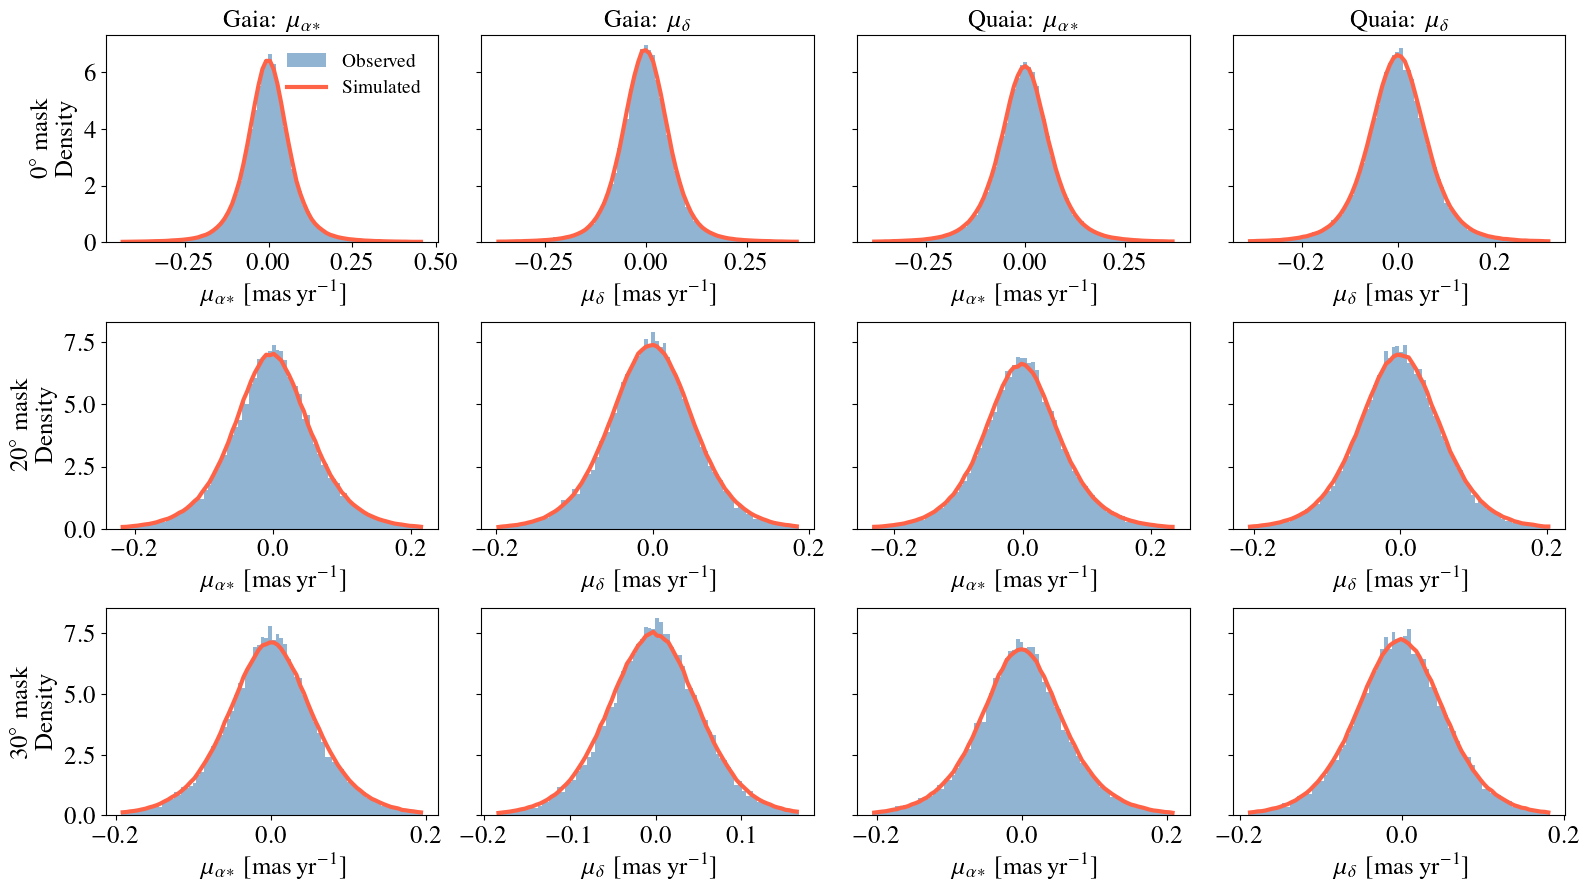

In [13]:
COMPLAB = {'pmra': r'$\mu_{\alpha*}$', 'pmdec': r'$\mu_{\delta}$'}
CATLAB  = {'gaia': 'Gaia', 'quaia': 'Quaia'}
pcols   = [(c, k) for c in CATALOGS for k in COMPS]

fig, axes = plt.subplots(len(GALCUTS), len(pcols), figsize=(16, 9), sharey='row')
for i, galcut in enumerate(GALCUTS):
    for j, (catalog, comp) in enumerate(pcols):
        ax  = axes[i, j]
        d   = ppc[(catalog, galcut)][comp]
        ctr = 0.5 * (d['bins'][1:] + d['bins'][:-1])
        q16, q50, q84 = np.percentile(d['hist'], [16, 50, 84], axis=0)

        ax.hist(d['obs'], bins=d['bins'], density=True, color='steelblue',
                alpha=0.6, label='Observed')
        # ax.fill_between(ctr, q16, q84, color='tomato', alpha=0.35, lw=0,
        #                 label=r'Predicted 16--84\%')
        ax.plot(ctr, q50, color='tomato', lw=3, label='Simulated')

        ax.set_xlabel(COMPLAB[comp] + r' $[\mathrm{mas\,yr^{-1}}]$', fontsize=18)
        ax.tick_params(labelsize=18)
        # ax.text(0.03, 0.95,
        #         f"rms obs {d['obs_rms'] * 1e3:.0f}\n"
        #         f"rms mod {d['sim_rms'] * 1e3:.0f}" + r' $\mu$as/yr',
        #         transform=ax.transAxes, va='top', fontsize=9)
        if i == 0:
            ax.set_title(f'{CATLAB[catalog]}: ' + COMPLAB[comp], fontsize=18)
        if j == 0:
            ax.set_ylabel(f'{galcut}' + r'$^\circ$ mask' + '\nDensity', fontsize=18)

axes[0, 0].legend(fontsize=14, frameon=False, loc='upper right')
# fig.suptitle(f'Observed vs posterior-predictive proper motions '
#              f'({PPC_MODEL} model, {N_PPC} draws)', fontsize=15)
fig.tight_layout()
fig.savefig(REPO / 'output/pm_histograms_cases_gaia_quaia.pdf', bbox_inches='tight')
plt.show()

## 9. Saved Artifacts

* `results/gaia_quaia_cases/sims_<tag>_<model>.npz` — training sets (θ, x)
* `results/gaia_quaia_cases/post_<tag>_<model>_net<k>.pt` — trained SNPE posteriors
* `results/gaia_quaia_cases/samples_<tag>_<model>_ens<N>.npz` — posterior θ samples
* `results/gaia_quaia_cases/summary.csv` — the table above
* `output/gxyz_cases_gaia_quaia.pdf`, `output/direction_cases_gaia_quaia.pdf`
* `output/pm_histograms_cases_gaia_quaia.pdf` — posterior-predictive check
* `output/gxyz_corner_<catalog>_galcut_<galcut>.pdf` — (gx, gy, gz) corner, full vs det
* `output/corner_quaia_galcut00_full_alm.pdf`, `output/corner_quaia_galcut00_full_cl.pdf`

`tag = <catalog>_galcut<NN>_nside<N>_N<N_SIMS>`, so changing `N_SIMS` or `nside`
starts a fresh cache instead of silently reusing stale runs.

In [14]:
gxyz_path = CACHE_DIR / 'gxyz_samples.npz'
np.savez(gxyz_path, **{f"{cat}_galcut{gc:02d}_{m}": results[(cat, gc, m)]['g']
                       for cat, gc in CASES for m in ('full', 'det')})
print(f"saved (gx, gy, gz) posterior samples → {gxyz_path}")

saved (gx, gy, gz) posterior samples → /home/phuy2808/Astrophysis/Intern_apc/results/gaia_quaia_cases_v3/gxyz_samples.npz


## 10. Corner Plots — (gx, gy, gz) per Case

One 3x3 corner per case: **full** model (blue) over **det** model (orange), 68% and
95% contours. Samples are read back from `gxyz_samples.npz` written above, so this
section runs standalone after a cached run. The legend is drawn on the Gaia panels
only; both panels use the same colour code.


current θ cache tag: gaia_galcut00_nside64_N100000_Cl130
gaia | galcut 0°


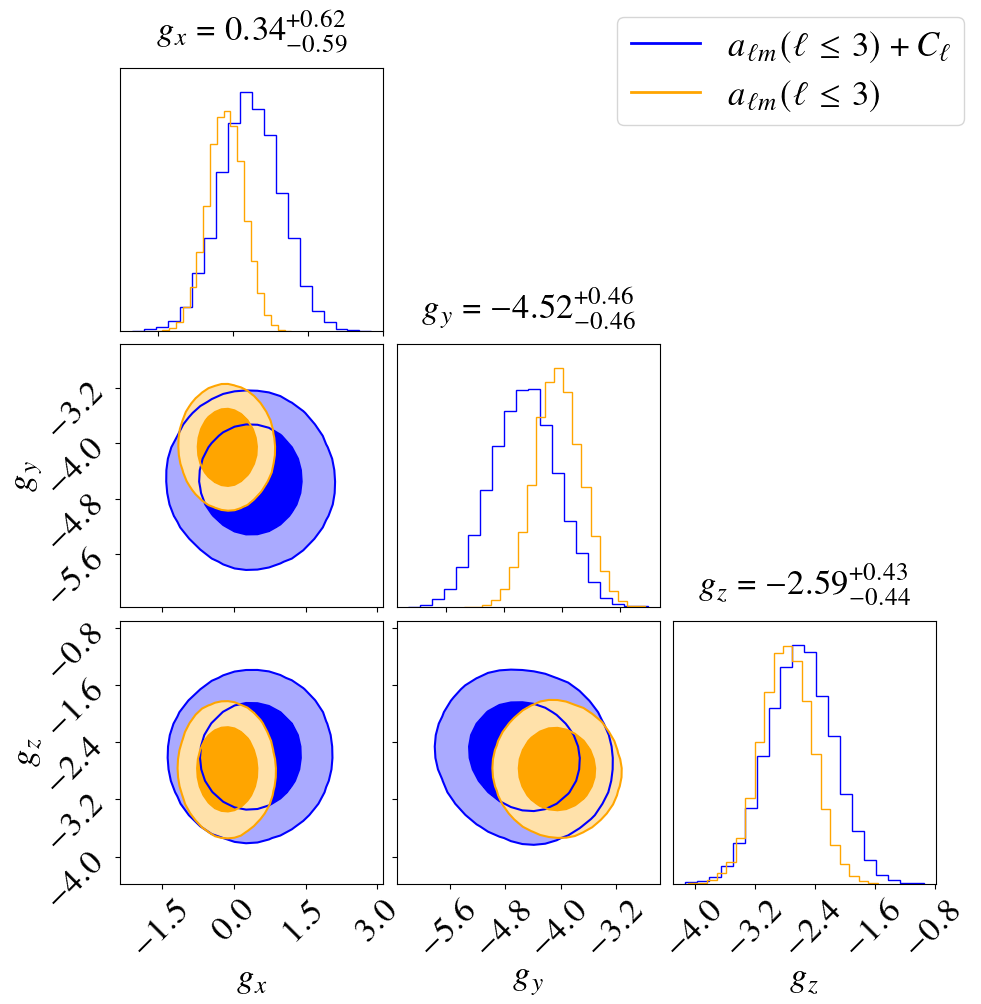

  saved → /home/phuy2808/Astrophysis/Intern_apc/output/gxyz_corner_gaia_galcut_0.pdf
gaia | galcut 20°


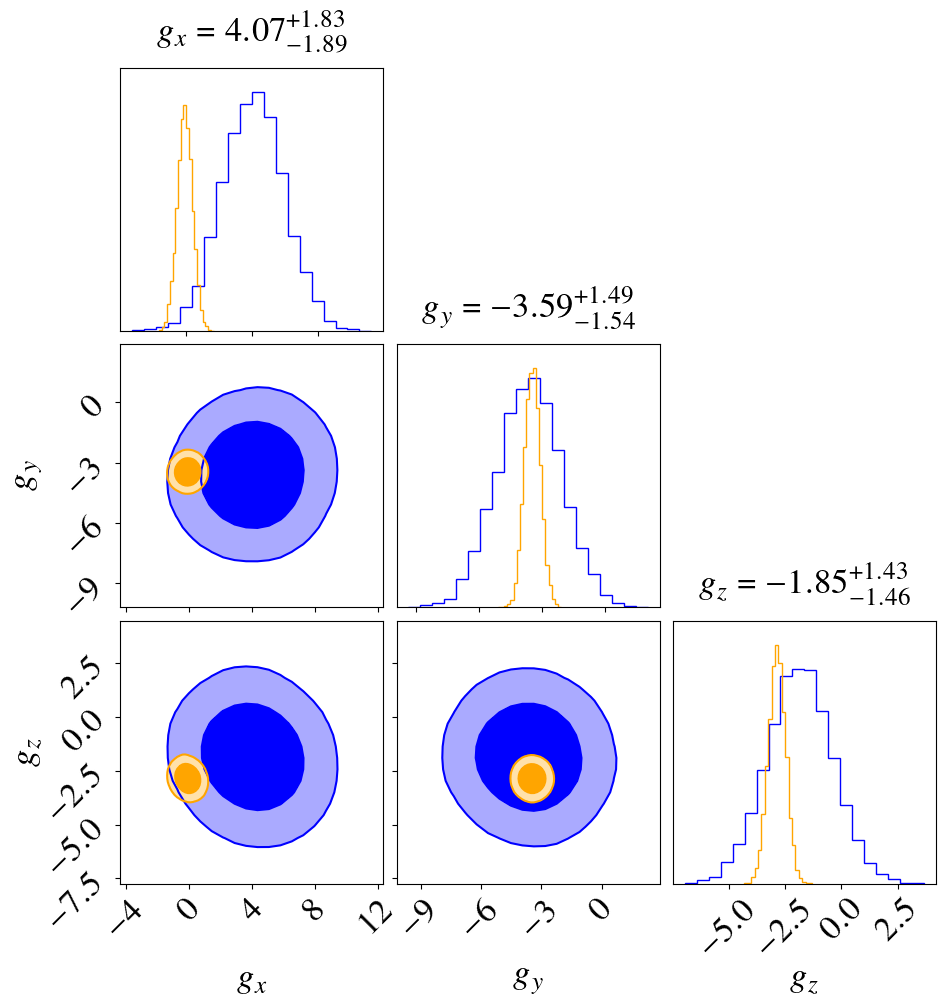

  saved → /home/phuy2808/Astrophysis/Intern_apc/output/gxyz_corner_gaia_galcut_20.pdf
gaia | galcut 30°


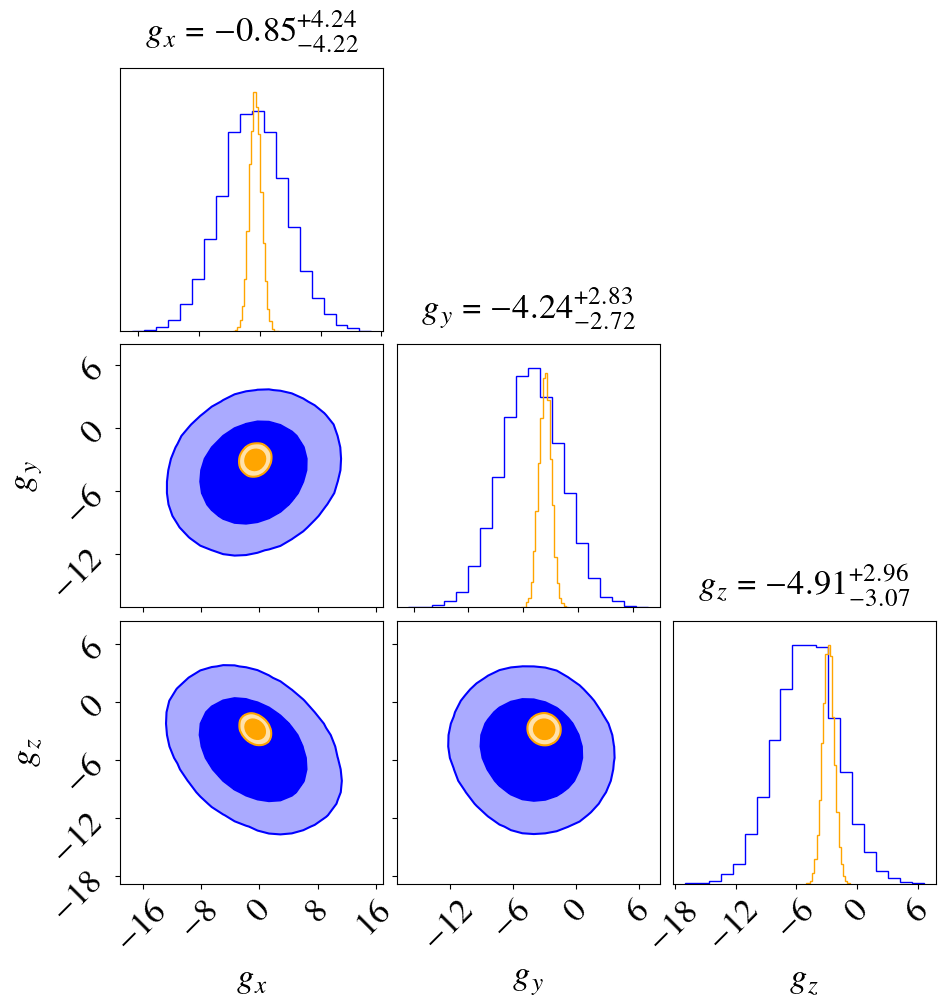

  saved → /home/phuy2808/Astrophysis/Intern_apc/output/gxyz_corner_gaia_galcut_30.pdf
quaia | galcut 0°


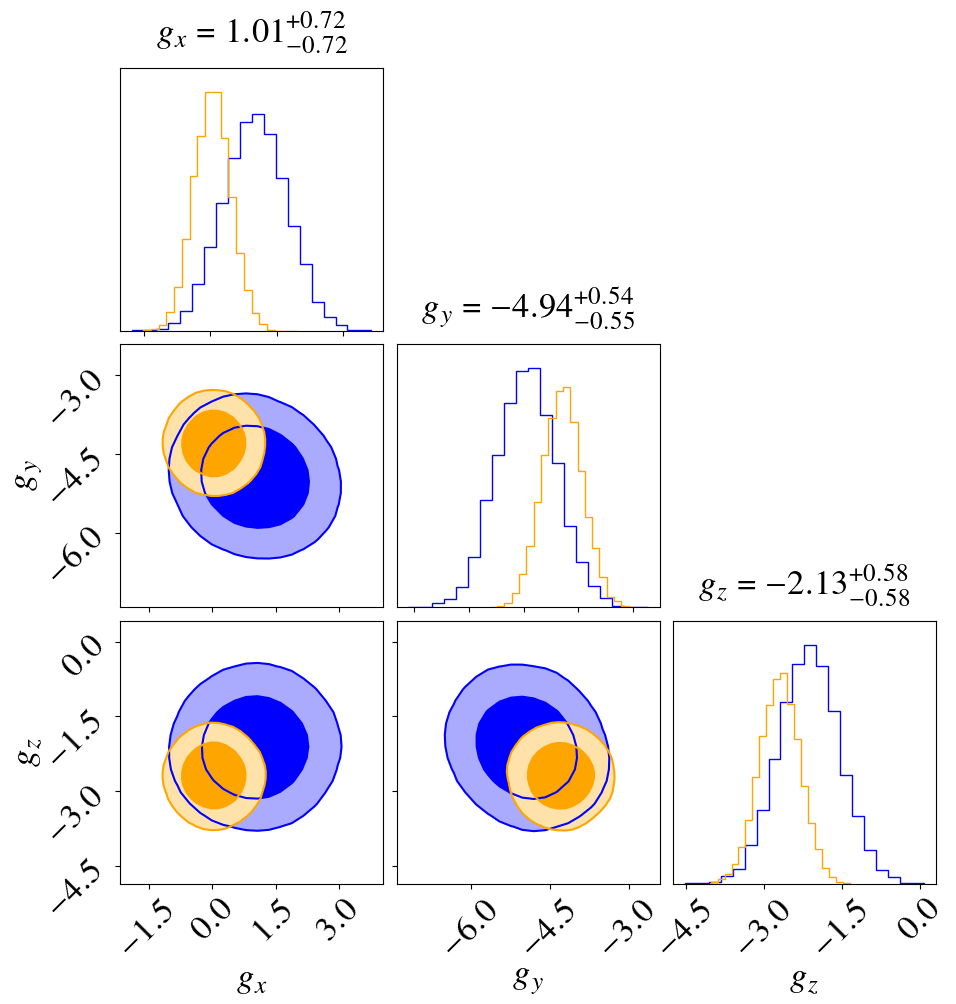

  saved → /home/phuy2808/Astrophysis/Intern_apc/output/gxyz_corner_quaia_galcut_0.pdf
quaia | galcut 20°


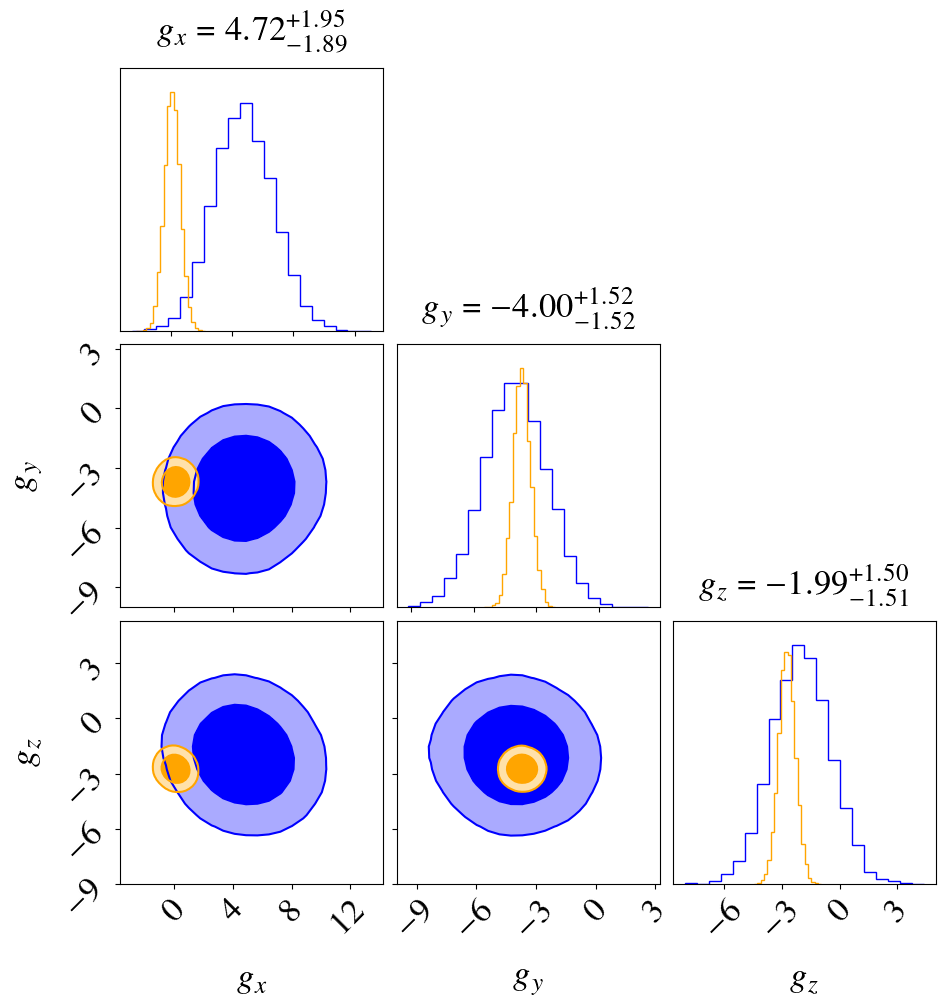

  saved → /home/phuy2808/Astrophysis/Intern_apc/output/gxyz_corner_quaia_galcut_20.pdf
quaia | galcut 30°


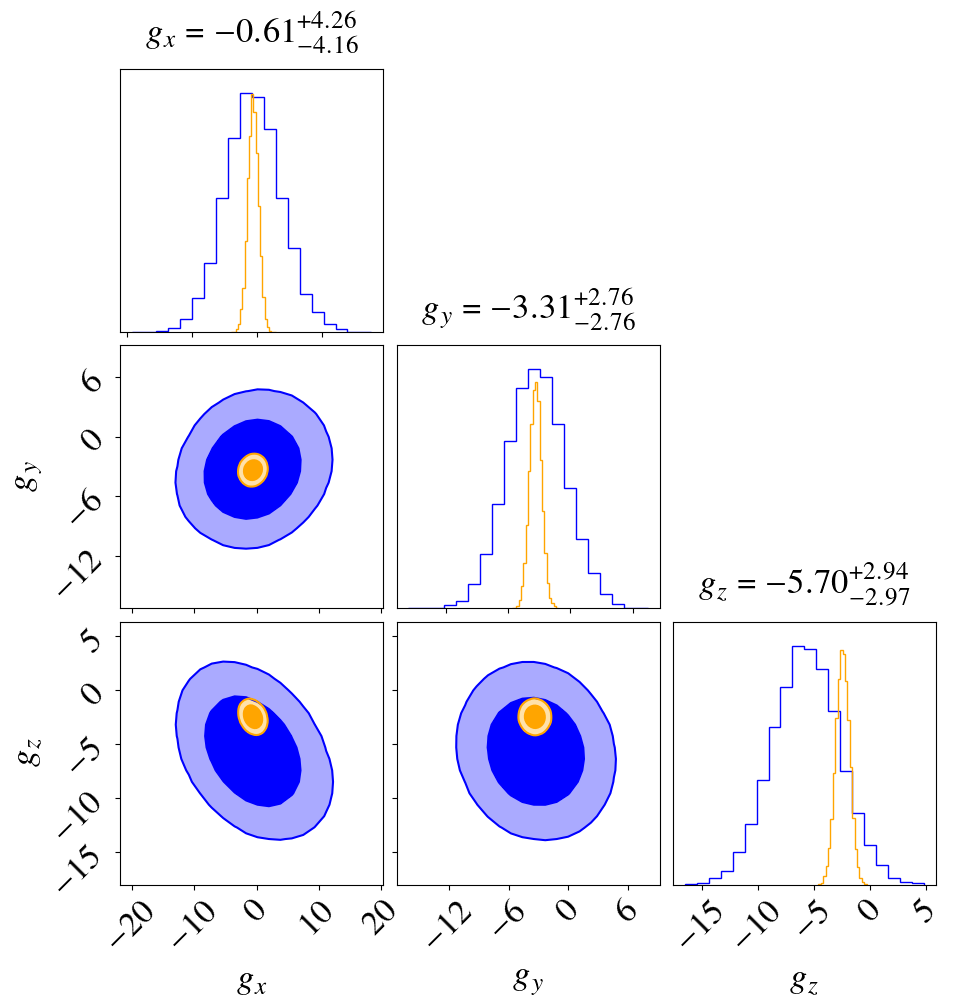

  saved → /home/phuy2808/Astrophysis/Intern_apc/output/gxyz_corner_quaia_galcut_30.pdf


In [15]:
import corner
from matplotlib.lines import Line2D

# (gx, gy, gz) in µas/yr — extract_g already applied the mas→µas factor.
# The npz keys carry no Cl_bound, so it tracks whichever run wrote it last:
# re-run section 5 + the save cell after changing Cl_bound.
G = np.load(CACHE_DIR / 'gxyz_samples.npz')
print(f"current θ cache tag: {case_tag('gaia', 0)}")

legend_elements = [
    Line2D([0], [0], color='blue',   lw=2, label=r'$a_{\ell m} (\ell  \leq 3) + C_{\ell}$'),
    Line2D([0], [0], color='orange', lw=2, label=r'$a_{\ell m} (\ell  \leq 3)$'),
    #Line2D([0], [0], color='red', lw=2, ls='--', label='MAP from data'),
]

for catalog, galcut in CASES:
    key    = f"{catalog}_galcut{galcut:02d}"
    g_full = G[f"{key}_full"]
    g_det  = G[f"{key}_det"]
    print(f"{catalog} | galcut {galcut}°")

    fig, axes = plt.subplots(3, 3, figsize=(10, 10))

    # Full model corner
    corner.corner(
        g_full,
        labels=[r'$g_x$', r'$g_y$', r'$g_z$'],
        show_titles=True,
        color='blue',
        fig=fig,
        plot_datapoints=False,
        fill_contours=True,
        plot_contours=True,
        levels=[0.68, 0.95],
        hist=False,
        smooth = 1.5,
        hist2d_kwargs={'bins': 80, 'density': True},
        title_kwargs={'fontsize': 25, 'pad': 20},
        label_kwargs={'fontsize': 25, 'labelpad': 20},
    )

    # Det. model overplotted
    corner.corner(
        g_det,
        labels=[r'$g_x$', r'$g_y$', r'$g_z$'],
        color='orange',
        fig=fig,
        plot_datapoints=False,
        fill_contours=True,
        plot_contours=True,
        levels=[0.68, 0.95],
        hist=False,
        smooth = 1.5,
        hist2d_kwargs={'bins': 80, 'density': True},
        label_kwargs={'fontsize': 25, 'labelpad': 20},
    )

    for ax in fig.axes:
        ax.tick_params(labelsize=25)

    if catalog == 'gaia' and galcut == 0:
        fig.legend(handles=legend_elements, loc='upper right', fontsize=25)

    out = REPO / f"output/gxyz_corner_{catalog}_galcut_{galcut}.pdf"
    fig.savefig(out, bbox_inches='tight')
    plt.show()
    print(f"  saved → {out}")


### 10a. Quaia — Full Parameter Space

The full model's 44 parameters split into the two blocks that mean different
things: the 30 deterministic `alm` (ℓ ≤ 3, µas/yr) and the 14 nuisance
`Cℓ` (ℓ = 4–10, µas² yr⁻²). Galactic cut 0° — the configuration
`quaia_sbi.ipynb` used for `output/corner_full_alm.pdf`; change
`QUAIA_CORNER_GALCUT` for another cut.


quaia_galcut00_nside64_N100000_Cl130: 10,000 posterior draws × 44 parameters


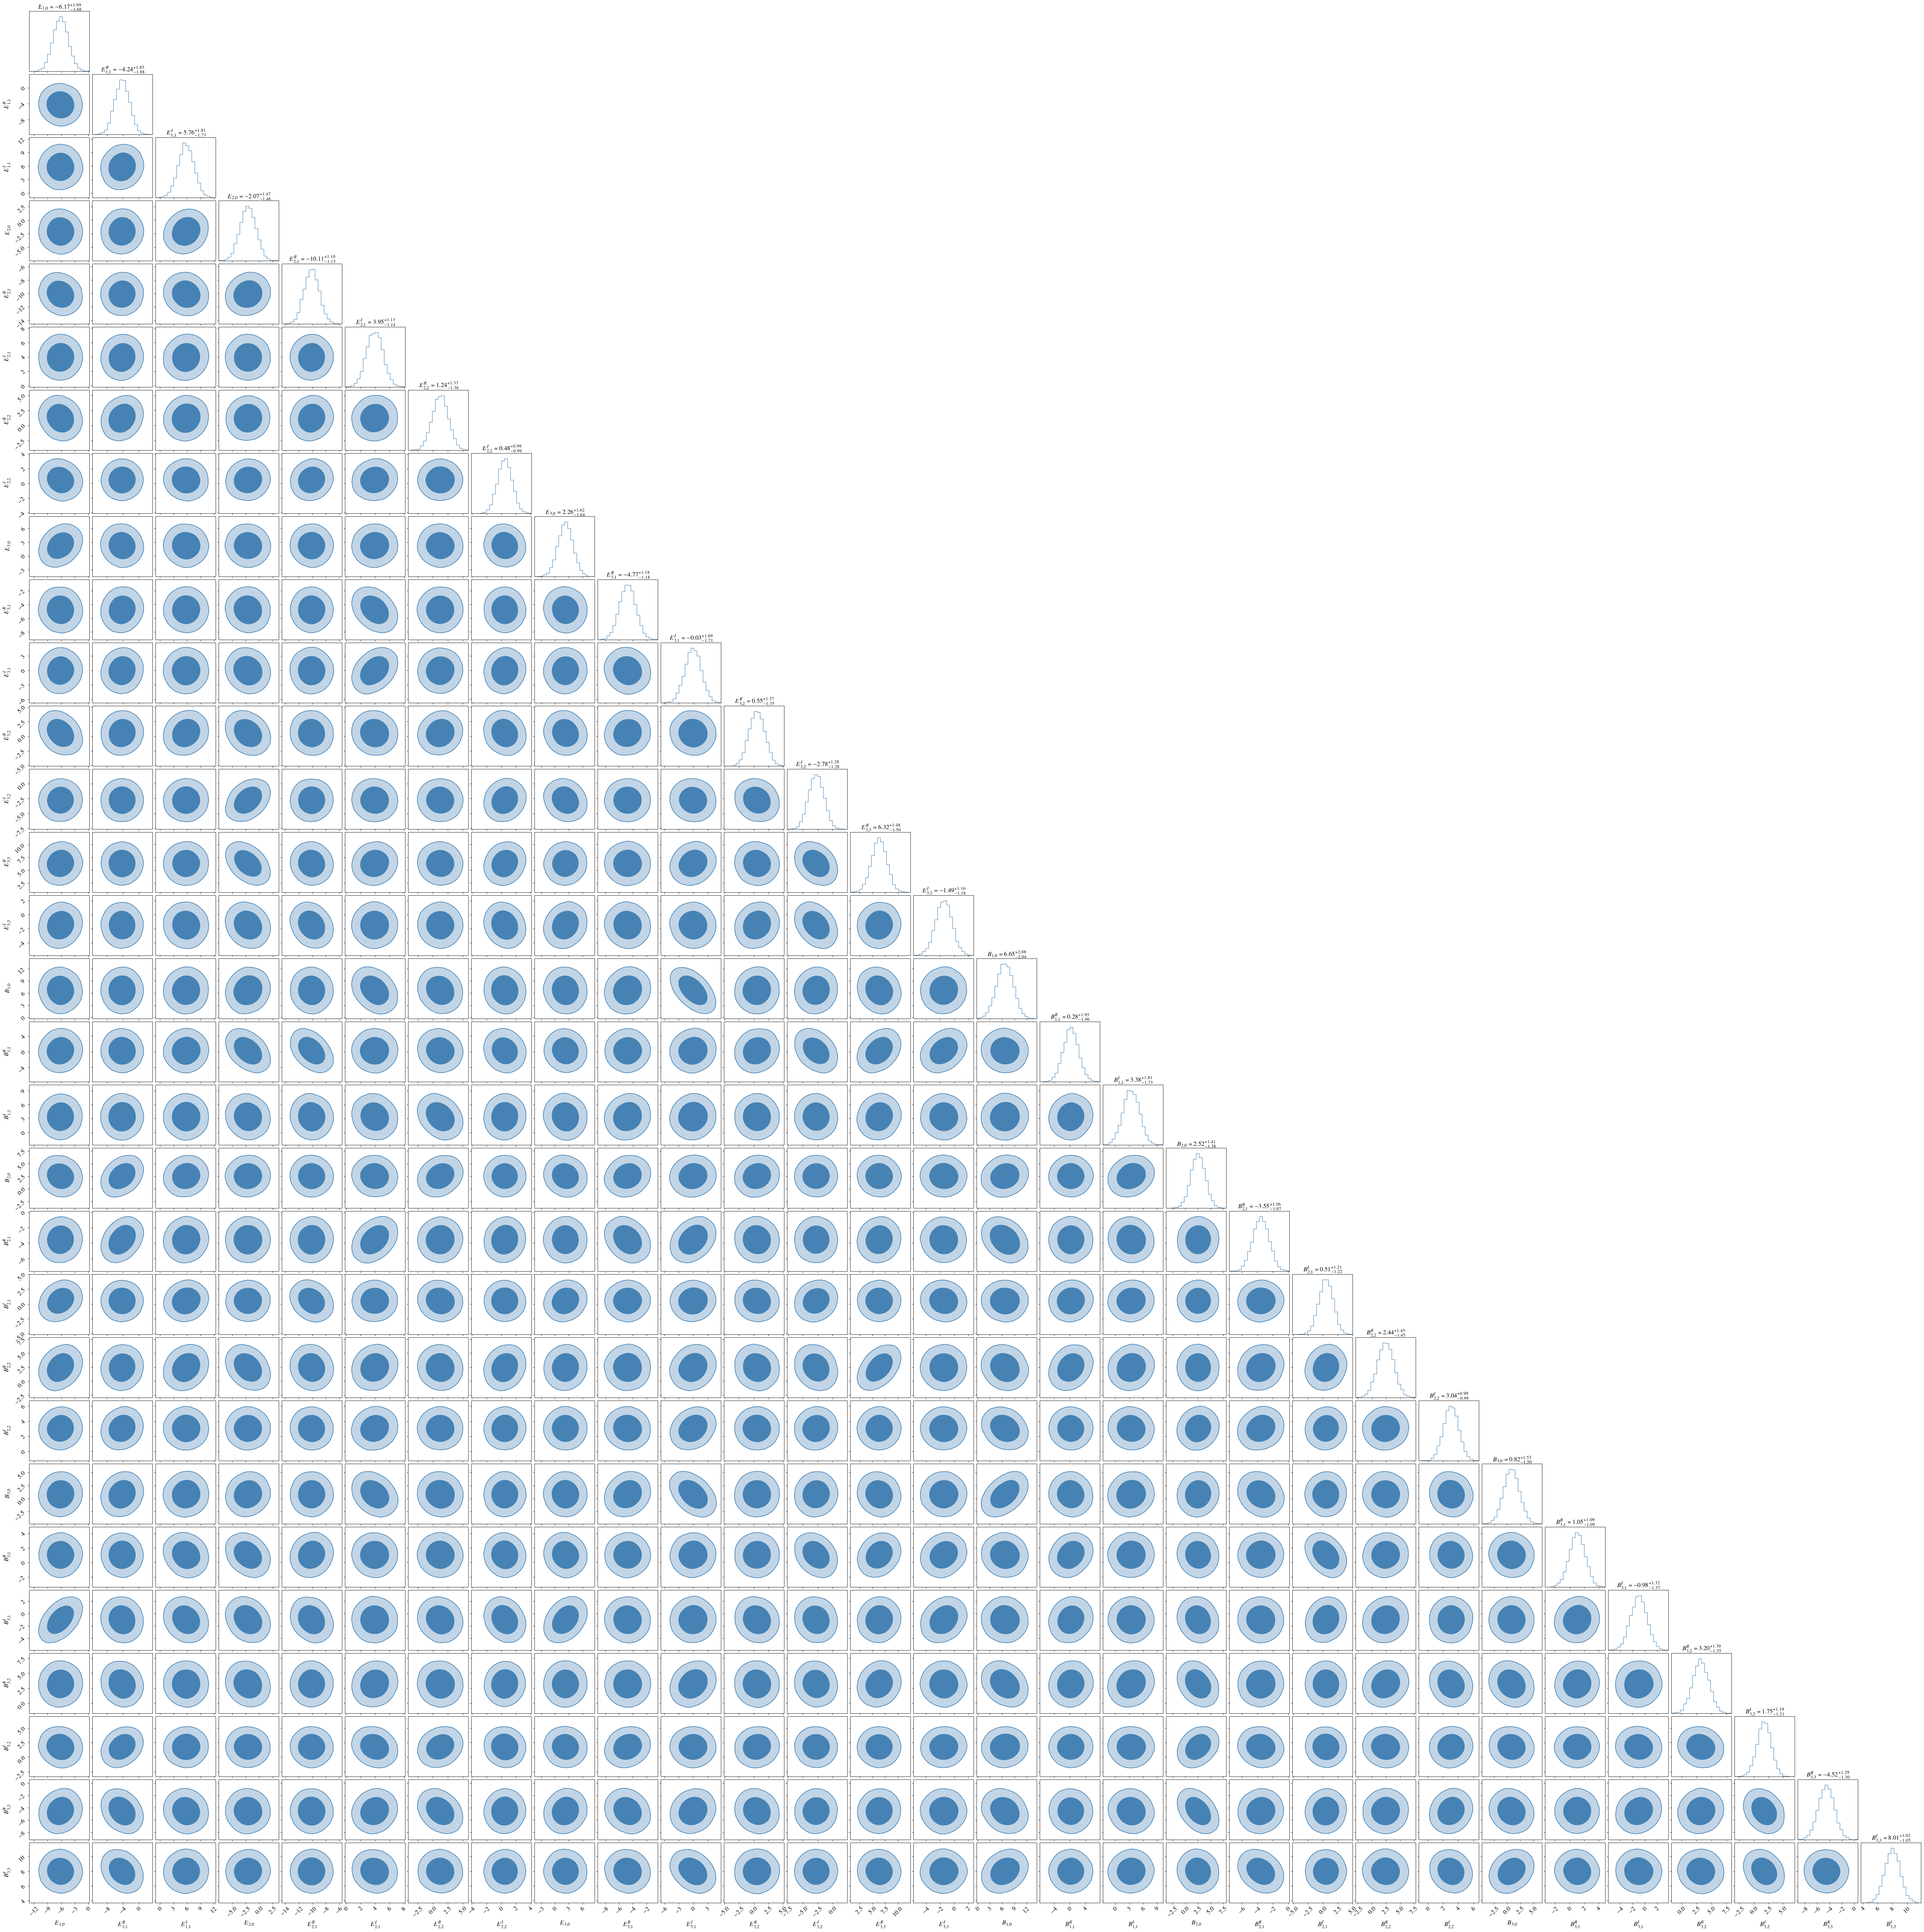

saved → /home/phuy2808/Astrophysis/Intern_apc/output/corner_quaia_galcut00_full_alm.pdf


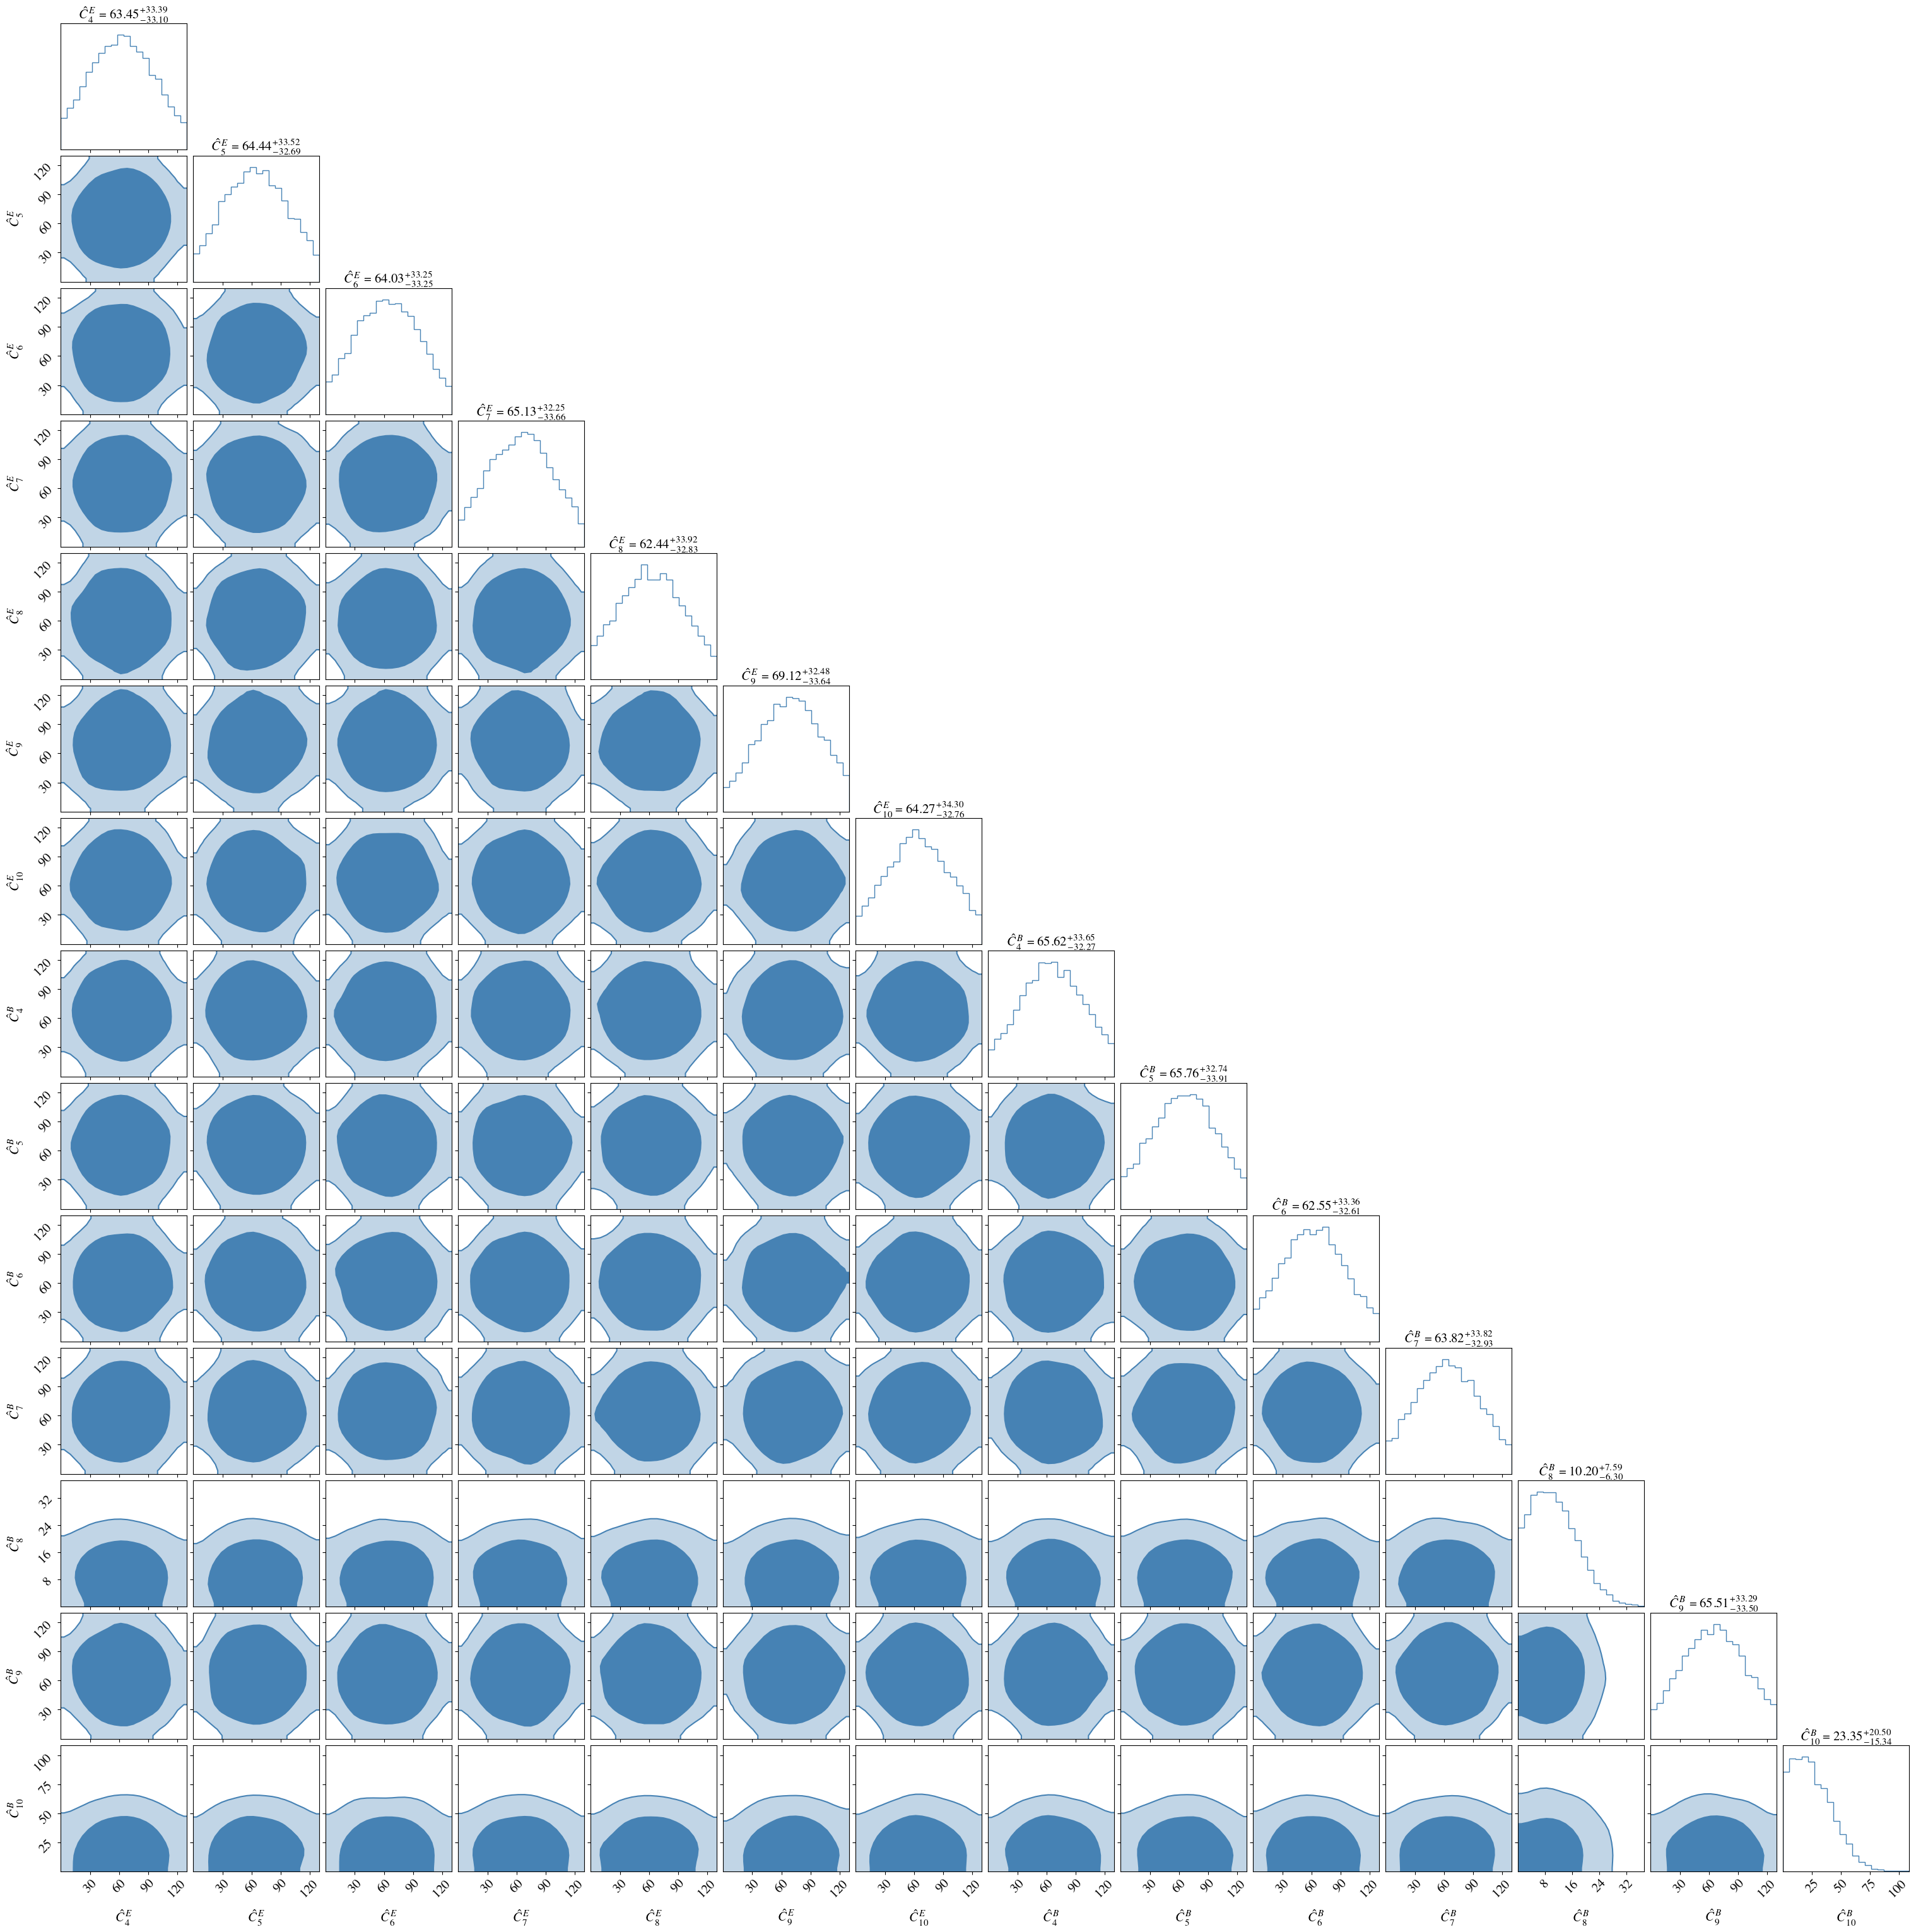

saved → /home/phuy2808/Astrophysis/Intern_apc/output/corner_quaia_galcut00_full_cl.pdf


In [16]:
import corner

QUAIA_CORNER_GALCUT = 0     # quaia case whose full-model θ posterior is shown

_tag  = case_tag('quaia', QUAIA_CORNER_GALCUT)
_th   = np.load(CACHE_DIR / f"samples_{_tag}_full_ens{N_ENSEMBLE}.npz")['samples']
theta_q = _th.reshape(-1, _th.shape[-1])      # (N_ENSEMBLE, N_POSTERIOR, 44) → (·, 44)
print(f"{_tag}: {theta_q.shape[0]:,} posterior draws × {theta_q.shape[1]} parameters")

# --- Parameter labels ---
alm_labels = []
for l in range(1, lmax_sig + 1):
    alm_labels.append(rf'$E_{{ {l},0 }}$')
    for m in range(1, l + 1):
        alm_labels.append(rf'$E_{{ {l},{m} }}^R$')
        alm_labels.append(rf'$E_{{ {l},{m} }}^I$')
for l in range(1, lmax_sig + 1):
    alm_labels.append(rf'$B_{{ {l},0 }}$')
    for m in range(1, l + 1):
        alm_labels.append(rf'$B_{{ {l},{m} }}^R$')
        alm_labels.append(rf'$B_{{ {l},{m} }}^I$')

cl_labels_E = [rf'$\hat{{C}}_{{{l}}}^E$' for l in range(lmax_sig + 1, lmax_fit + 1)]
cl_labels_B = [rf'$\hat{{C}}_{{{l}}}^B$' for l in range(lmax_sig + 1, lmax_fit + 1)]
cl_labels = cl_labels_E + cl_labels_B

# --- Panel 1: alm parameters (mas/yr → µas/yr) ---
fig1 = corner.corner(
    theta_q[:, :n_alm_l3] * 1e3,
    labels=alm_labels,
    show_titles=True,
    color='steelblue',
    plot_datapoints=False,
    fill_contours=True,
    plot_contours=True,
    levels=[0.68, 0.95],
    smooth=1.5,
    title_kwargs={'fontsize': 15},
    label_kwargs={'fontsize': 15},
)
for ax in fig1.axes:
    ax.tick_params(labelsize=15)
out1 = REPO / f"output/corner_quaia_galcut{QUAIA_CORNER_GALCUT:02d}_full_alm.pdf"
fig1.savefig(out1, bbox_inches='tight')
plt.show()
print(f"saved → {out1}")

# --- Panel 2: Cl parameters ((mas/yr)² → µas²/yr²) ---
fig2 = corner.corner(
    theta_q[:, n_alm_l3:] * 1e6,
    labels=cl_labels,
    show_titles=True,
    color='steelblue',
    plot_datapoints=False,
    fill_contours=True,
    plot_contours=True,
    levels=[0.68, 0.95],
    smooth=1.5,
    title_kwargs={'fontsize': 15},
    label_kwargs={'fontsize': 15},
)
for ax in fig2.axes:
    ax.tick_params(labelsize=15)
out2 = REPO / f"output/corner_quaia_galcut{QUAIA_CORNER_GALCUT:02d}_full_cl.pdf"
fig2.savefig(out2, bbox_inches='tight')
plt.show()
print(f"saved → {out2}")
